<a href="https://colab.research.google.com/github/FazelPriyono/Pembelajaran-Mesin-2026/blob/main/TG4_244107020033_FazelPriyono.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS04 - Klasterisasi
## Praktikum 1

## KMeans
**Langkah 0 - Persiapan Data**

In [ ]:
#Persiapan data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

df = pd.read_csv('Iris.csv')

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


**Langkah 1 - Seleksi Fitur**

In [ ]:
# Seleksi Fitur

X = df.iloc[:, 1:-1]
y = df.iloc[:, -1]

**Langkah 2 - Visualisasi Data Awal**

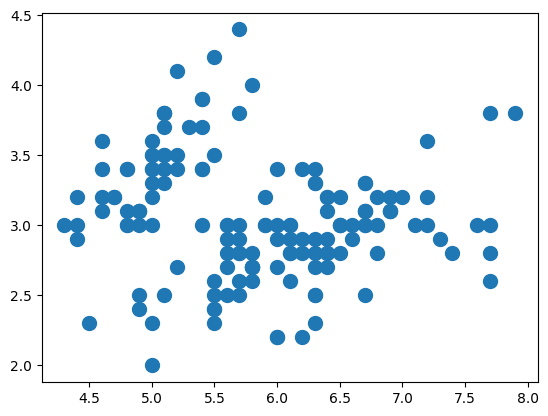

In [ ]:
# Plot Data
# Karena data 4 dimensi, maka akan kita coba
# plot cluster berdasarkan Sepal Length dan Sepal Width  saja

plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100)

**Langkah 3 - Membuat Model K-Means**

In [ ]:
# Buat Model KMeans
# Kali ini kita coba menggunakan k=2 - anggap saja kita tidak tahu jumlah label ada 3 :)

from sklearn.cluster import KMeans

# Inisiasi obyek KMeans
cl_kmeans = KMeans(n_clusters=2)

# Fit dan predict model
y_kmeans = cl_kmeans.fit_predict(X)

**Langkah 4 - Visualisasi Hasil Clustering**

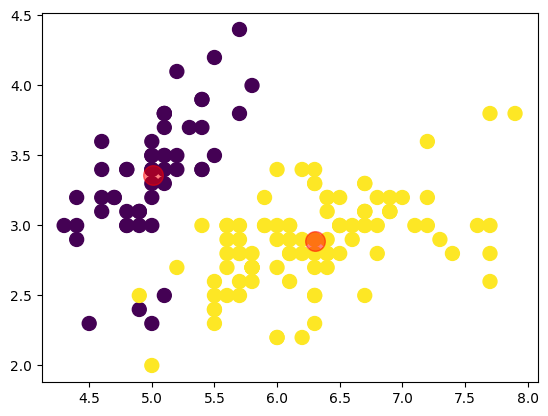

In [ ]:
# Plot hasi cluster berdasarkan Sepal Length dan Sepal Width
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100, c=y_kmeans)

# Plot centroid
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)

**Langkah 5 - Menghitung Nilai SSE**

In [ ]:
# Cek Nilai SSE
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 152.36870647733915


**Langkah 6 - Implementasi Metode Elbow**

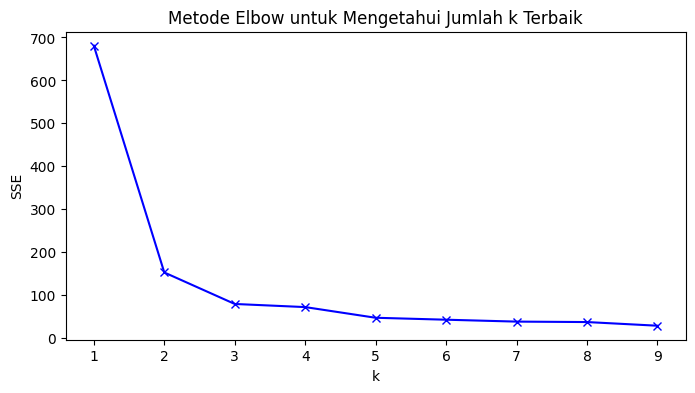

In [ ]:
# Implementasi Metode Elbow

# List nilai SSE
sse = []

# Cari k terbaik dari 1-10
K = range(1,10)

# Cek nilai SSE setiap k
for k in K:
 kmeanModel = KMeans(n_clusters=k)
 kmeanModel.fit(X)
 sse.append(kmeanModel.inertia_)


# Plotting the distortions
plt.figure(figsize=(8,4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Metode Elbow untuk Mengetahui Jumlah k Terbaik")
plt.show()

**Langkah 7 - Menampilkan Nilai SSE Setiap k**

In [ ]:
# Cek Nilai SSE setiap k
for idx, sse_val in enumerate(sse, start=1):
    print(f'k={idx}; SSE={sse_val}')

k=1; SSE=680.8243999999996
k=2; SSE=152.36870647733915
k=3; SSE=78.94084142614601
k=4; SSE=71.66131466733202
k=5; SSE=46.78482573099418
k=6; SSE=42.25234444444447
k=7; SSE=37.83336635382164
k=8; SSE=36.783883100233105
k=9; SSE=28.2385149924658


# Praktikum 2

**Langkah 0 - Import Library**

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import numpy as np

## Pengantar k-Means

**Langkah 1 - Membuat Dataset Sintetis**

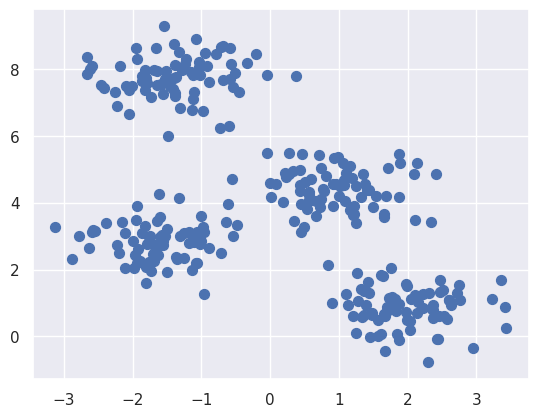

In [ ]:
from sklearn.datasets import make_blobs
X, y_true = make_blobs(n_samples=300, centers=4,
                       cluster_std=0.60, random_state=0)
plt.scatter(X[:, 0], X[:, 1], s=50);

**Langkah 2 - Membuat Model K-Means**

In [ ]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=4)
kmeans.fit(X)
y_kmeans = kmeans.predict(X)

**Langkah 3 - Visualisasi Hasil Clustering**

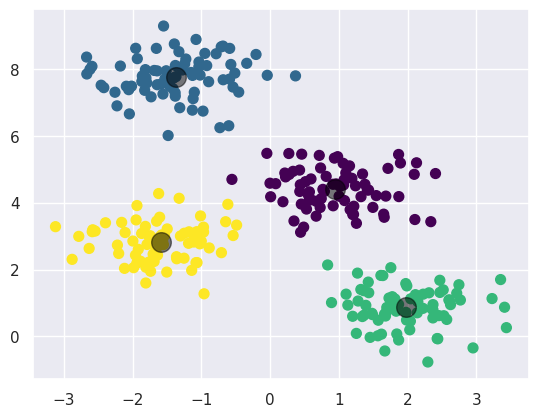

In [ ]:
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')

centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.5)

## Algoritma Expectation-Maximization
**Langkah 4 - Implementasi K-Means Secara Manual**

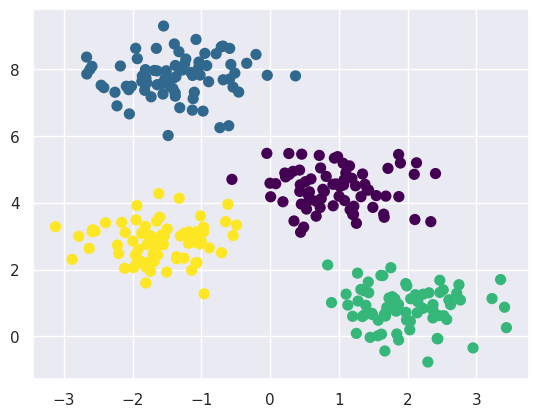

In [ ]:
from sklearn.metrics import pairwise_distances_argmin

def find_clusters(X, n_clusters, rseed=2):
    # 1. Randomly choose clusters
    rng = np.random.RandomState(rseed)
    i = rng.permutation(X.shape[0])[:n_clusters]
    centers = X[i]

    while True:
        # 2a. input label center yang baru
        labels = pairwise_distances_argmin(X, centers)

        # 2b. update center dari titik baru
        new_centers = np.array([X[labels == i].mean(0)
                                for i in range(n_clusters)])

        # 2c. cek konvergensi
        if np.all(centers == new_centers):
            break
        centers = new_centers

    return centers, labels

centers, labels = find_clusters(X, 4)
plt.scatter(X[:, 0], X[:, 1], c=labels,s=50, cmap='viridis');

**Langkah 5 - Mengubah Nilai Random Seed**

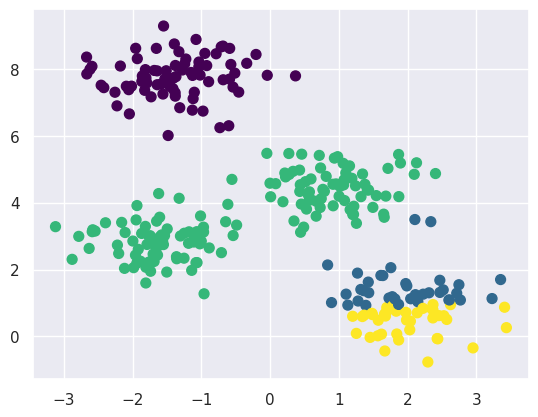

In [ ]:
centers, labels = find_clusters(X, 4, rseed=0)
plt.scatter(X[:, 0], X[:, 1], c=labels,s=50, cmap='viridis');

**Langkah 6 - Mengubah Jumlah Cluster**

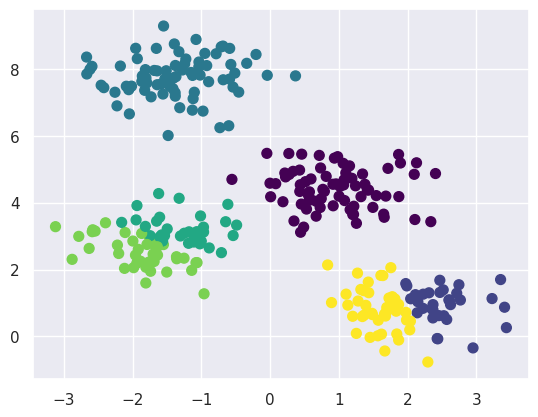

In [ ]:
labels = KMeans(6, random_state=0).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis');

**Langkah 7 - Membuat Dataset Moon**

In [ ]:
from sklearn.datasets import make_moons
X, y = make_moons(200, noise=.05, random_state=0)

**Langkah 8 - Clustering dengan K-Means pada Data Moon**

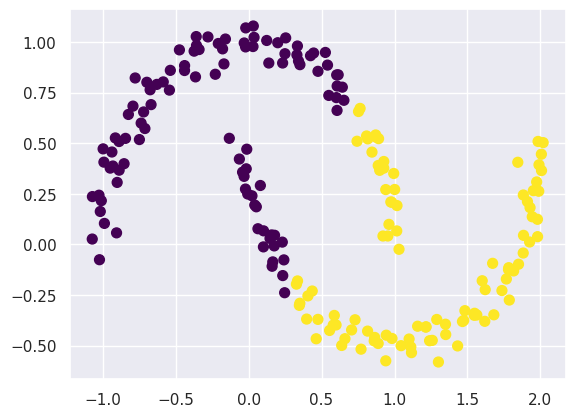

In [ ]:
labels = KMeans(2, random_state=0).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels,s=50, cmap='viridis');

**Langkah 9 - Clustering dengan Spectral Clustering**

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


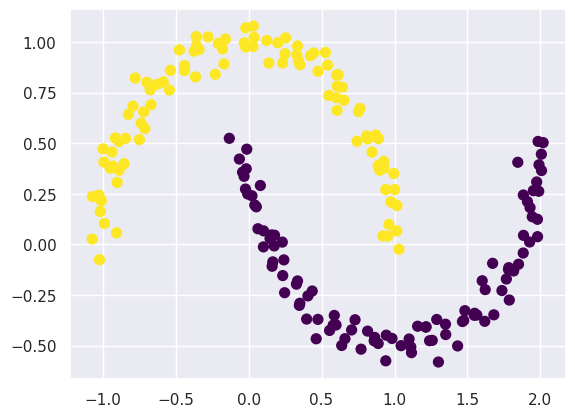

In [ ]:
from sklearn.cluster import SpectralClustering
model = SpectralClustering(n_clusters=2, affinity='nearest_neighbors',
                           assign_labels='kmeans')
labels = model.fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis');

## Studi Kasus 1 - Karakter Angka
**Langkah 10 - Memuat Dataset Digits**

In [ ]:
from sklearn.datasets import load_digits
digits = load_digits()
digits.data.shape

(1797, 64)

**Langkah 11 - Menerapkan K-Means pada Dataset Digits**

In [ ]:
# terapkan K-Means
kmeans = KMeans(n_clusters=10, random_state=0)
clusters = kmeans.fit_predict(digits.data)
kmeans.cluster_centers_.shape

(10, 64)

**Langkah 12 - Menampilkan Centroid Angka**

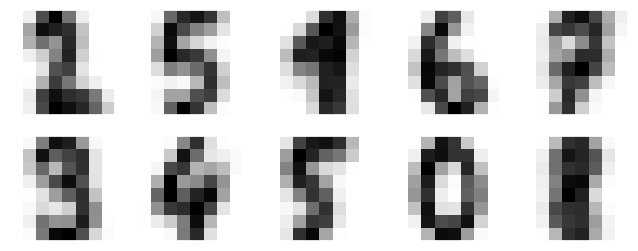

In [ ]:
fig, ax = plt.subplots(2, 5, figsize=(8, 3))
centers = kmeans.cluster_centers_.reshape(10, 8, 8)
for axi, center in zip(ax.flat, centers):
    axi.set(xticks=[], yticks=[])
    axi.imshow(center, interpolation='nearest', cmap=plt.cm.binary)

**Langkah 13 - Menentukan Label Cluster**

In [ ]:
from scipy.stats import mode

labels = np.zeros_like(clusters)
for i in range(10):
    mask = (clusters == i)
    labels[mask] = mode(digits.target[mask])[0]

**Langkah 14 - Menghitung Akurasi**

In [ ]:
from sklearn.metrics import accuracy_score
accuracy_score(digits.target, labels)

0.7440178074568725

**Langkah 15 - Membuat Confusion Matrix**

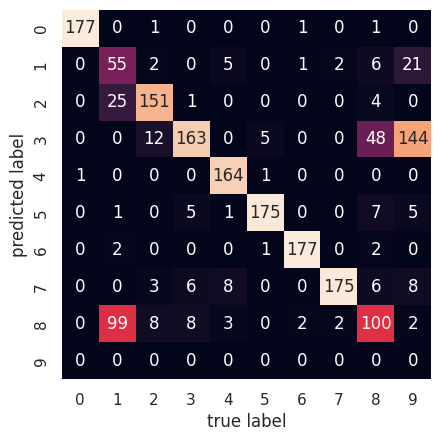

In [ ]:
from sklearn.metrics import confusion_matrix
mat = confusion_matrix(digits.target, labels)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=digits.target_names,
            yticklabels=digits.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label');

**Langkah 16 - Reduksi Dimensi dengan t-SNE**

In [ ]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, init='random', random_state=0)
digits_proj = tsne.fit_transform(digits.data)

# hitung klaster
kmeans = KMeans(n_clusters=10, random_state=0)
clusters = kmeans.fit_predict(digits_proj)

# permutasi label
labels = np.zeros_like(clusters)
for i in range(10):
    mask = (clusters == i)
    labels[mask] = mode(digits.target[mask])[0]

# hitung akurasi
accuracy_score(digits.target, labels)

0.9410127991096272

## Studi Kasus 2: Kompresi Citra
**Langkah 17 - Memuat Gambar Sampel**

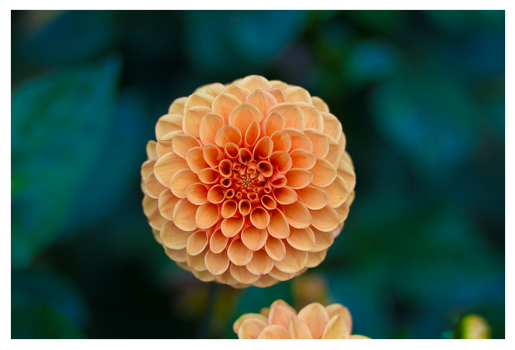

In [ ]:
from sklearn.datasets import load_sample_image
flower = load_sample_image("flower.jpg")
ax = plt.axes(xticks=[], yticks=[])
ax.imshow(flower);

**Langkah 18 - Melihat Ukuran Gambar**

In [ ]:
flower.shape

(427, 640, 3)

**Langkah 19 - Menyiapkan Data Warna**

In [ ]:
data = flower / 255.0
data = data.reshape(427 * 640, 3)
data.shape

(273280, 3)

**Langkah 20 - Membuat Fungsi Visualisasi Warna**

In [ ]:
def plot_pixels(data, title, colors=None, N=10000):
    if colors is None:
        colors = data

    # choose a random subset
    rng = np.random.RandomState(0)
    i = rng.permutation(data.shape[0])[:N]
    colors = colors[i]
    R, G, B = data[i].T

    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    ax[0].scatter(R, G, color=colors, marker='.')
    ax[0].set(xlabel='Red', ylabel='Green', xlim=(0, 1), ylim=(0, 1))

    ax[1].scatter(R, B, color=colors, marker='.')
    ax[1].set(xlabel='Red', ylabel='Blue', xlim=(0, 1), ylim=(0, 1))

    fig.suptitle(title, size=20);

**Langkah 21 - Menampilkan Ruang Warna Asli**

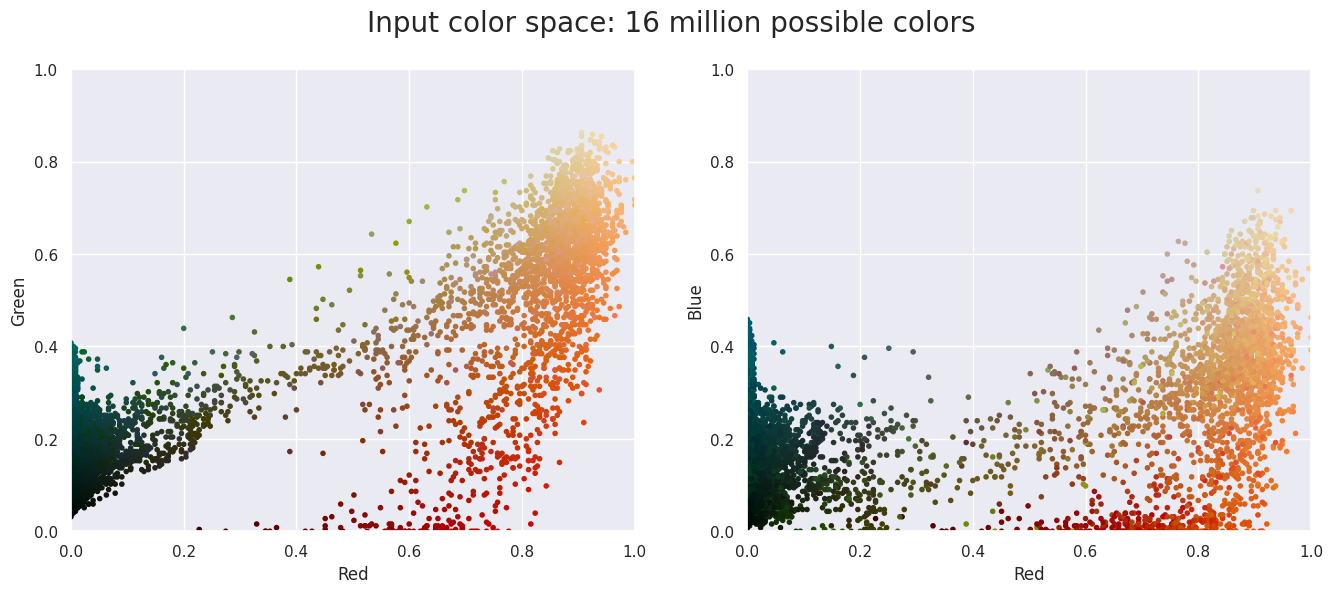

In [ ]:
plot_pixels(data, title='Input color space: 16 million possible colors')

**Langkah 22 - Reduksi Warna dengan MiniBatchKMeans**

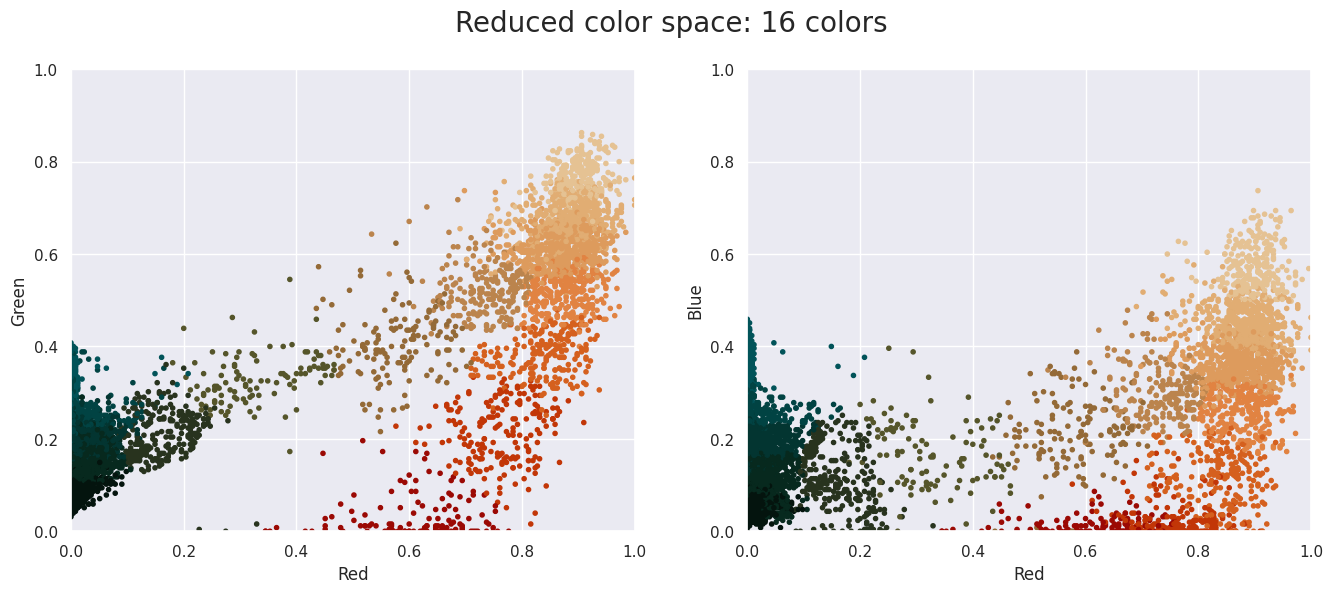

In [ ]:
import warnings; warnings.simplefilter('ignore')  # Fix NumPy issues.

from sklearn.cluster import MiniBatchKMeans
kmeans = MiniBatchKMeans(16)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

plot_pixels(data, colors=new_colors,title="Reduced color space: 16 colors")

**Langkah 23 - Menampilkan Hasil Kompresi Citra**

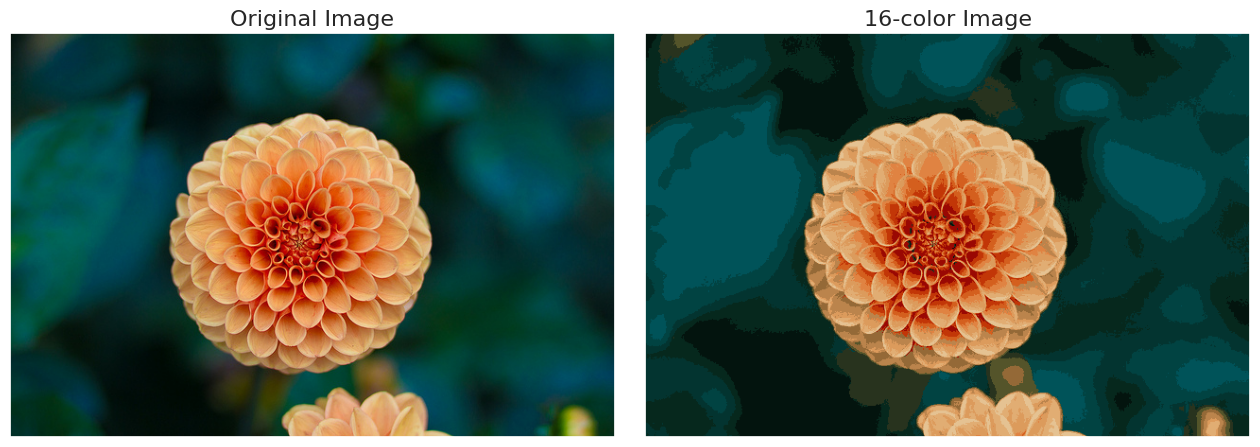

In [ ]:
flower_recolored = new_colors.reshape(flower.shape)

fig, ax = plt.subplots(1, 2, figsize=(16, 6),
                       subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(flower)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(flower_recolored)
ax[1].set_title('16-color Image', size=16);

# Praktikum 3
**Langkah 0 - Import Library dan Membuat Dataset Sintetis**

In [ ]:
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

centers = [[1, 1], [-1, -1], [1, -1]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=0.4, random_state=0
)

X = StandardScaler().fit_transform(X)

**Langkah 1 - Visualisasi Dataset**

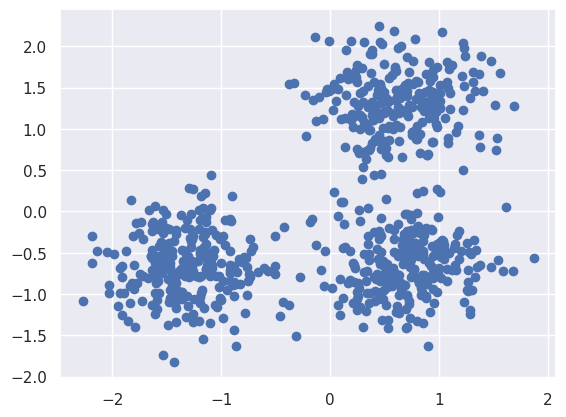

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(X[:, 0], X[:, 1])
plt.show()

## Implementasi DBSCAN
**Langkah 2 - Membuat Model DBSCAN**

In [ ]:
import numpy as np

from sklearn import metrics
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.3, min_samples=10).fit(X)
labels = db.labels_

# Number of clusters in labels, ignoring noise if present.
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

**Langkah 3 - Menampilkan Jumlah Cluster dan Noise**

In [ ]:
print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)

Estimated number of clusters: 3
Estimated number of noise points: 18


- `eps = 0.3` → jarak maksimum antar titik untuk dianggap tetangga.
- `min_samples = 10` → jumlah minimum titik dalam radius `eps` agar dianggap area padat (core sample).
- Label hasil klasterisasi tersedia di `labels`. Nilai `-1` berarti titik tersebut dianggap noise atau outlier.

## Evaluasi Kualitas Clustering
**Langkah 4 - Menghitung Nilai Evaluasi Clustering**

In [ ]:
print(f"Homogeneity: {metrics.homogeneity_score(labels_true, labels):.3f}")
print(f"Completeness: {metrics.completeness_score(labels_true, labels):.3f}")
print(f"V-measure: {metrics.v_measure_score(labels_true, labels):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(labels_true, labels):.3f}")
print(
    "Adjusted Mutual Information:"
    f" {metrics.adjusted_mutual_info_score(labels_true, labels):.3f}"
)
print(f"Silhouette Coefficient: {metrics.silhouette_score(X, labels):.3f}")

Homogeneity: 0.953
Completeness: 0.883
V-measure: 0.917
Adjusted Rand Index: 0.952
Adjusted Mutual Information: 0.916
Silhouette Coefficient: 0.626


- **Homogeneity** → apakah tiap klaster hanya berisi satu label asli.
- **Completeness** → apakah semua sampel dengan label asli yang sama masuk ke klaster yang sama.
- **V-measure** → rata-rata harmonik dari homogeneity dan completeness.
- **Adjusted Rand Index (ARI)** → kesesuaian antara klasterisasi dengan label asli.
- **Adjusted Mutual Information (AMI)** → kesamaan informasi antara klasterisasi dengan label asli.
- **Silhouette Coefficient** → seberapa baik data dikelompokkan (nilai mendekati 1 berarti bagus, mendekati 0 berarti berada di batas, negatif berarti salah klaster).

## Visualisasi Hasil DBSCAN
**Langkah 5 - Menentukan Core Sample dan Label Cluster**

In [ ]:
unique_labels = set(labels)
core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True

**Langkah 6 - Menentukan Warna Setiap Cluster**

In [ ]:
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

**Langkah 7 - Menampilkan Core Sample dan Non Core Sample**

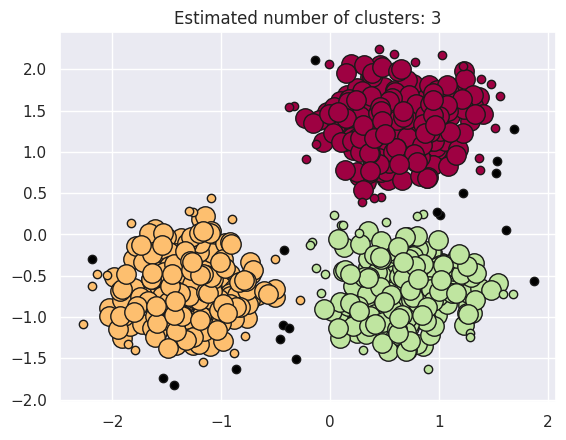

In [ ]:
for k, col in zip(unique_labels, colors):
    if k == -1:
        # Black used for noise.
        col = [0, 0, 0, 1]

    class_member_mask = labels == k

    xy = X[class_member_mask & core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=14,
    )
    xy = X[class_member_mask & ~core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=6,
    )


plt.title(f"Estimated number of clusters: {n_clusters_}")
plt.show()

**Interpretasi visual:**

- Titik besar berwarna → **core samples** dalam klaster.

- Titik kecil berwarna → **non-core samples**, tetap termasuk klaster.

- Titik hitam → **noise/outlier**.

# Tugas Praktikum

## **Bagian 1: Tugas K-Means (Mall Customers Dataset)**

#### **Langkah 1 - Memuat dan Memeriksa Data**
Pada langkah ini, saya memuat dataset `Mall_Customers.csv` ke dalam DataFrame Pandas. Saya menampilkan data awal, tipe data setiap kolom, serta statistik deskriptif untuk memahami karakteristik data pelanggan sebelum melakukan pemrosesan lebih lanjut.

In [ ]:
import pandas as pd

# 1. Muat dataset
df_mall = pd.read_csv('/content/Mall_Customers.csv')

# 2. Tampilkan beberapa baris pertama
print("=== BEBERAPA BARIS PERTAMA ===")
print(df_mall.head())

# 3. Tampilkan informasi dasar dataset
print("\n=== INFORMASI DATASET ===")
print(df_mall.info())
print("\n=== STATISTIK DESKRIPTIF ===")
print(df_mall.describe())

# 4. Seleksi kolom 'Annual Income (k$)' dan 'Spending Score (1-100)'
X_mall = df_mall[['Annual Income (k$)', 'Spending Score (1-100)']]
print("\n=== FITUR SELEKSI (X_mall) ===")
print(X_mall.head())
print(f"\nDimensi X_mall: {X_mall.shape}")

=== BEBERAPA BARIS PERTAMA ===
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

=== INFORMASI DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ K

#### **Langkah 2 - Menentukan Jumlah Klaster Optimal (Metode Elbow)**
Saya menggunakan **Metode Elbow** untuk mencari nilai $k$ (jumlah kelompok) terbaik. Menguji nilai $k$ dari 1 sampai 10 dan menghitung nilai SSE (Inertia). Titik di mana penurunan SSE mulai melandai (membentuk siku atau 'elbow') menunjukkan jumlah klaster paling optimal (dalam kasus ini adalah $k=5$).

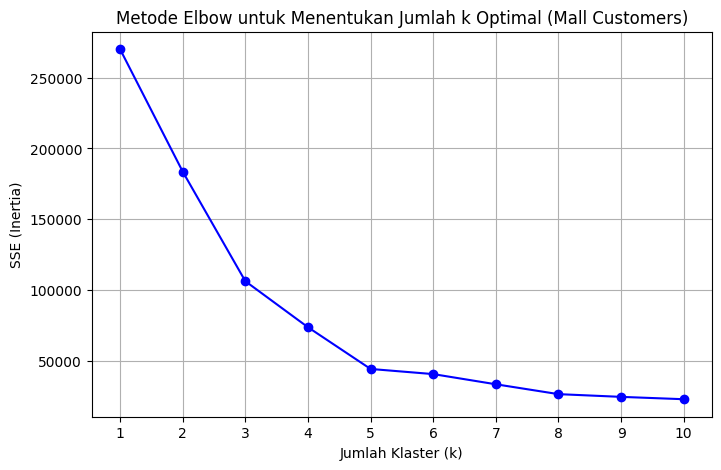

=== NILAI SSE UNTUK SETIAP K ===
k=1: SSE=269981.2800
k=2: SSE=183653.3289
k=3: SSE=106348.3731
k=4: SSE=73880.6450
k=5: SSE=44448.4554
k=6: SSE=40825.1695
k=7: SSE=33642.5792
k=8: SSE=26686.8378
k=9: SSE=24766.4716
k=10: SSE=23103.1221


In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. List untuk menyimpan nilai SSE
sse = []

# 2. Iterasi nilai k dari 1 hingga 10
K = range(1, 11)
for k in K:
    # 3. Inisiasi KMeans dengan random_state=42
    kmeans = KMeans(n_clusters=k, random_state=42)
    # 4. Latih model dengan X_mall
    kmeans.fit(X_mall)
    # 5. Ambil nilai inertia dan tambahkan ke sse
    sse.append(kmeans.inertia_)

# 6. Visualisasi grafik Elbow
plt.figure(figsize=(8, 5))
plt.plot(K, sse, marker='o', linestyle='-', color='b')
plt.xlabel('Jumlah Klaster (k)')
plt.ylabel('SSE (Inertia)')
plt.title('Metode Elbow untuk Menentukan Jumlah k Optimal (Mall Customers)')
plt.xticks(K)
plt.grid(True)
plt.show()

# 7. Tampilkan nilai SSE secara tekstual
print("=== NILAI SSE UNTUK SETIAP K ===")
for k_val, sse_val in zip(K, sse):
    print(f"k={k_val}: SSE={sse_val:.4f}")

#### **Langkah 3 - Melatih Model K-Means dan Visualisasi Hasil**
Dengan menggunakan jumlah klaster optimal yang telah dipilih ($k=5$), saya melatih model K-Means pada fitur pendapatan tahunan (*Annual Income*) dan skor pengeluaran (*Spending Score*). Selanjutnya, memvisualisasikan hasil pengelompokan pelanggan beserta titik pusat (centroid) dari masing-masing klaster.

Melatih model K-Means menggunakan nilai k terbaik yang telah dipilih (k=5) dan memvisualisasikan hasil klaster beserta centroid masing-masing kelompok dalam bentuk scatter plot.


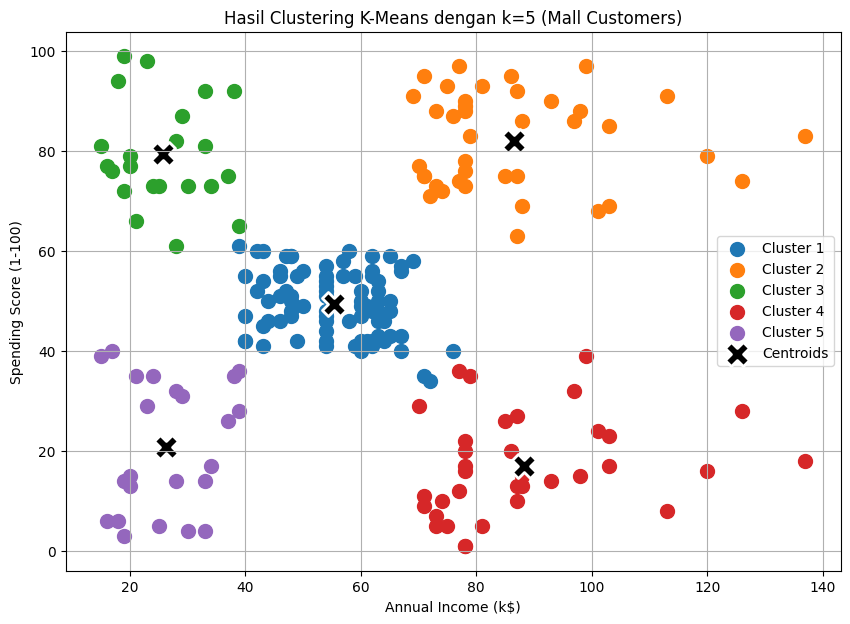

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# 1. Inisialisasi model KMeans dengan k=5 dan random_state=42
kmeans_best = KMeans(n_clusters=5, random_state=42)

# 2. Fit dan predict menggunakan X_mall
y_kmeans_best = kmeans_best.fit_predict(X_mall)

# 3. Dapatkan koordinat centroid
centroids = kmeans_best.cluster_centers_

# 4. Visualisasi hasil clustering
plt.figure(figsize=(10, 7))

# Plot data points untuk setiap klaster
for i in range(5):
    plt.scatter(X_mall.iloc[y_kmeans_best == i, 0],
                X_mall.iloc[y_kmeans_best == i, 1],
                s=100, label=f'Cluster {i+1}')

# Plot centroids
plt.scatter(centroids[:, 0], centroids[:, 1],
            s=300, c='black', marker='X', label='Centroids', edgecolors='white', linewidths=2)

# Tambahkan label, judul, dan legenda
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Hasil Clustering K-Means dengan k=5 (Mall Customers)')
plt.legend()
plt.grid(True)
plt.show()

## **Bagian 2: Tugas DBSCAN (Moons Dataset)**

#### **Langkah 1 - Pembuatan Dataset Sintetis dan Standardisasi**
Membuat dataset non-linear berbentuk bulan sabit (*moons*) menggunakan generator dari scikit-learn. Karena DBSCAN sangat sensitif terhadap skala jarak, saya melakukan standardisasi fitur menggunakan `StandardScaler` agar kedua dimensi data memiliki skala yang seragam.

In [ ]:
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

# 1. Buat dataset sintetis moons
X_moon, y_moon = make_moons(n_samples=1000, noise=0.05, random_state=42)

# 2. Standardisasi fitur
scaler = StandardScaler()
X_moon_scaled = scaler.fit_transform(X_moon)

# 3. Tampilkan dimensi
print(f"Dimensi X_moon_scaled: {X_moon_scaled.shape}")
print(f"Dimensi y_moon: {y_moon.shape}")

Dimensi X_moon_scaled: (1000, 2)
Dimensi y_moon: (1000,)


#### **Langkah 2 - Implementasi DBSCAN Baseline**
Menerapkan algoritma DBSCAN dengan parameter acuan (baseline): radius tetangga `eps=0.2` dan jumlah sampel minimum `min_samples=5`. Langkah ini bertujuan untuk melihat performa awal model dalam mengelompokkan data tanpa optimasi parameter tambahan.

In [ ]:
from sklearn.cluster import DBSCAN

# 1. Inisialisasi DBSCAN baseline dengan eps=0.2 dan min_samples=5
db_baseline = DBSCAN(eps=0.2, min_samples=5)

# 2. Fit model ke data yang telah dinormalisasi
db_baseline.fit(X_moon_scaled)
labels_baseline = db_baseline.labels_

# 3. Hitung jumlah klaster (mengabaikan noise -1)
n_clusters_baseline = len(set(labels_baseline)) - (1 if -1 in labels_baseline else 0)

# 4. Hitung jumlah titik noise
n_noise_baseline = list(labels_baseline).count(-1)

# 5. Cetak hasil
print("=== DBSCAN BASELINE RESULTS ===")
print(f"Estimated number of clusters: {n_clusters_baseline}")
print(f"Estimated number of noise points: {n_noise_baseline}")

=== DBSCAN BASELINE RESULTS ===
Estimated number of clusters: 2
Estimated number of noise points: 0


#### **Langkah 3 - Evaluasi Kualitas dan Visualisasi Hasil Baseline**
Mengukur performa clustering baseline menggunakan berbagai metrik evaluasi seperti V-measure, ARI, dan Silhouette Coefficient. Saya juga memvisualisasikan hasil pengelompokan untuk membedakan antara sampel utama (*core points*), sampel tepi (*non-core points*), dan pencilan (*noise*).

=== EVALUASI DBSCAN BASELINE ===
Homogeneity: 1.000
Completeness: 1.000
V-measure: 1.000
Adjusted Rand Index (ARI): 1.000
Adjusted Mutual Information (AMI): 1.000
Silhouette Coefficient: 0.391


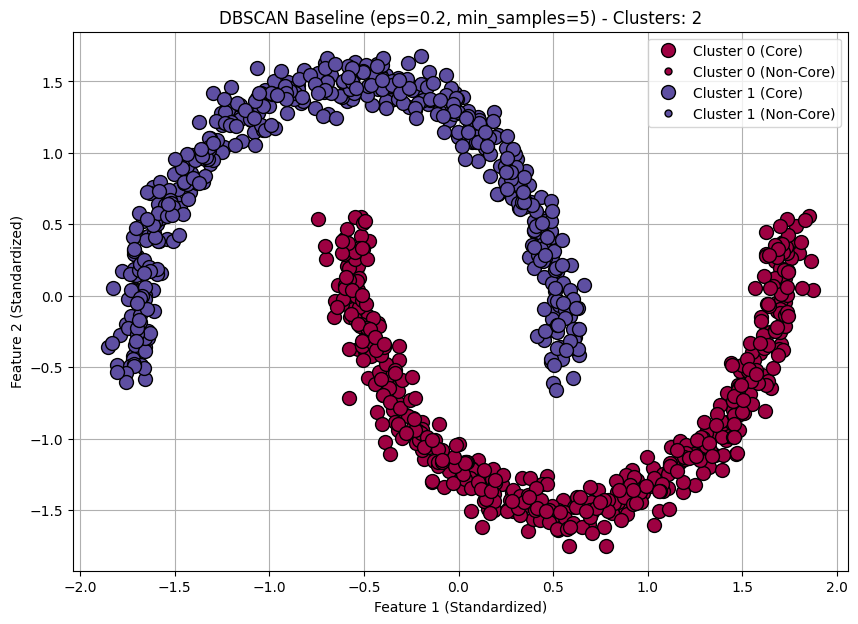

In [ ]:
from sklearn import metrics
import numpy as np
import matplotlib.pyplot as plt

# 1. Hitung dan cetak metrik evaluasi
print("=== EVALUASI DBSCAN BASELINE ===")
print(f"Homogeneity: {metrics.homogeneity_score(y_moon, labels_baseline):.3f}")
print(f"Completeness: {metrics.completeness_score(y_moon, labels_baseline):.3f}")
print(f"V-measure: {metrics.v_measure_score(y_moon, labels_baseline):.3f}")
print(f"Adjusted Rand Index (ARI): {metrics.adjusted_rand_score(y_moon, labels_baseline):.3f}")
print(f"Adjusted Mutual Information (AMI): {metrics.adjusted_mutual_info_score(y_moon, labels_baseline):.3f}")
print(f"Silhouette Coefficient: {metrics.silhouette_score(X_moon_scaled, labels_baseline):.3f}")

# 2. Tentukan core samples mask
unique_labels = set(labels_baseline)
core_samples_mask = np.zeros_like(labels_baseline, dtype=bool)
core_samples_mask[db_baseline.core_sample_indices_] = True

# 3. Definisikan palet warna
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

# 4. Visualisasi hasil clustering
plt.figure(figsize=(10, 7))
for k, col in zip(unique_labels, colors):
    if k == -1:
        # Warna hitam untuk noise
        col = [0, 0, 0, 1]

    class_member_mask = (labels_baseline == k)

    # Plot Core Samples (Titik Besar)
    xy_core = X_moon_scaled[class_member_mask & core_samples_mask]
    plt.plot(
        xy_core[:, 0],
        xy_core[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=10,
        label=f"Cluster {k} (Core)" if k != -1 else "Noise"
    )

    # Plot Non-Core Samples (Titik Kecil)
    xy_non_core = X_moon_scaled[class_member_mask & ~core_samples_mask]
    plt.plot(
        xy_non_core[:, 0],
        xy_non_core[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=5,
        label=f"Cluster {k} (Non-Core)" if k != -1 else ""
    )

plt.title(f"DBSCAN Baseline (eps=0.2, min_samples=5) - Clusters: {n_clusters_baseline}")
plt.xlabel("Feature 1 (Standardized)")
plt.ylabel("Feature 2 (Standardized)")
plt.legend(loc="best")
plt.grid(True)
plt.show()

#### **Langkah 4 - Eksperimen Kombinasi Parameter (Tuning Parameter)**
Untuk menemukan performa model DBSCAN terbaik, saya melakukan uji coba dengan memvariasikan nilai radius (`eps`) dan jumlah sampel minimum (`min_samples`). Hasil dari berbagai kombinasi ini dirangkum ke dalam tabel perbandingan untuk dianalisis parameternya yang paling ideal.

In [ ]:
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn import metrics

# 1. Definisikan variasi parameter
eps_values = [0.05, 0.1, 0.3, 0.5]
min_samples_values = [3, 10, 20]

# 2. List untuk menyimpan hasil
results = []

# 3. Looping untuk setiap kombinasi parameter
for eps in eps_values:
    for min_samples in min_samples_values:
        db = DBSCAN(eps=eps, min_samples=min_samples).fit(X_moon_scaled)
        labels = db.labels_

        # Hitung jumlah klaster dan noise
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)

        # Hitung metrik evaluasi jika jumlah klaster > 1
        if n_clusters > 1:
            homogeneity = metrics.homogeneity_score(y_moon, labels)
            completeness = metrics.completeness_score(y_moon, labels)
            v_measure = metrics.v_measure_score(y_moon, labels)
            ari = metrics.adjusted_rand_score(y_moon, labels)
            ami = metrics.adjusted_mutual_info_score(y_moon, labels)
            silhouette = metrics.silhouette_score(X_moon_scaled, labels)
        else:
            homogeneity = completeness = v_measure = ari = ami = silhouette = float('nan')

        # Simpan hasil
        results.append({
            'eps': eps,
            'min_samples': min_samples,
            'Clusters': n_clusters,
            'Noise': n_noise,
            'Homogeneity': homogeneity,
            'Completeness': completeness,
            'V-measure': v_measure,
            'ARI': ari,
            'AMI': ami,
            'Silhouette': silhouette
        })

# 4. Sajikan dalam bentuk DataFrame
df_results = pd.DataFrame(results)
print("=== TABEL PERBANDINGAN EKSPERIMEN PARAMETER DBSCAN ===")
df_results

=== TABEL PERBANDINGAN EKSPERIMEN PARAMETER DBSCAN ===


,eps,min_samples,Clusters,Noise,Homogeneity,Completeness,V-measure,ARI,AMI,Silhouette
0,0.05,3,69,186,0.815554,0.152548,0.257021,0.030044,0.243805,0.112929
1,0.05,10,3,970,0.030669,0.126764,0.049389,0.002283,0.045864,-0.294190
2,0.05,20,0,1000,NaN,NaN,NaN,NaN,NaN,NaN
3,0.10,3,2,14,0.986207,0.902896,0.942714,0.972179,0.942634,0.251690
4,0.10,10,7,57,0.943317,0.409546,0.571132,0.523399,0.569801,0.162306
5,0.10,20,6,850,0.153928,0.155466,0.154693,0.016754,0.150916,-0.360195
6,0.30,3,2,0,1.000000,1.000000,1.000000,1.000000,1.000000,0.391160
7,0.30,10,2,0,1.000000,1.000000,1.000000,1.000000,1.000000,0.391160
8,0.30,20,2,0,1.000000,1.000000,1.000000,1.000000,1.000000,0.391160
9,0.50,3,2,0,1.000000,1.000000,1.000000,1.000000,1.000000,0.391160


### **Kesimpulan Eksperimen Parameter DBSCAN**

Berdasarkan hasil eksperimen variasi parameter `eps` dan `min_samples` pada dataset *Moons*, dapat disimpulkan beberapa poin penting berikut:

1. **Pengaruh Radius (`eps`):**
   - Nilai `eps` yang terlalu kecil (`0.05` dan `0.10` dengan `min_samples` tinggi) menyebabkan algoritma sensitif terhadap kerapatan, menghasilkan jumlah klaster yang sangat banyak (over-clustering) atau mengategorikan hampir seluruh data sebagai **noise** (hingga 1000 titik).
   - Nilai `eps` yang lebih besar (`0.30` dan `0.50`) berhasil menyatukan titik-titik data dengan baik menjadi **2 klaster utama** tanpa menghasilkan titik noise sama sekali (0 noise).

2. **Pengaruh Kerapatan Minimum (`min_samples`):**
   - Pada `eps` kecil, menaikkan `min_samples` akan drastis meningkatkan jumlah titik yang dianggap noise karena syarat kepadatan lokal menjadi lebih sulit dipenuhi.

3. **Kualitas Evaluasi (Metrics):**
   - Kombinasi parameter **`eps >= 0.30`** (dengan `min_samples` berapapun dalam eksperimen ini) memberikan hasil paling optimal dengan skor metrik sempurna: **Homogeneity, Completeness, V-measure, ARI, dan AMI mencapai nilai 1.000**.
   - Nilai **Silhouette Coefficient** stabil di angka **0.391**, yang menunjukkan bahwa batas antar klaster berbentuk non-linear (bulan sabit) ini sangat jelas terpisah meskipun secara metrik geometris jarak konvensional nilainya tidak mendekati 1.